# Clinical Risk Prediction of Diabetes Using Supervised Machine Learning Models on Patient Health Records

**Course:** Deep Learning Project (ICT-4442)  
**Team No.:** 11  
**Team members:** Siddhan Baranwal (230911480), Shubham Singh (230911464), Gauransh Goyal (230911456)

## Project overview
This notebook compares Logistic Regression, Random Forest, Support Vector Machine (RBF kernel), and a Multi-Layer Perceptron (MLP) neural network for binary diabetes classification on the Pima Indians Diabetes dataset.

**Important limitation:** this is an educational benchmark on a small, specific dataset—not a diagnostic tool and not evidence of clinical readiness.


## 1. Setup and dataset validation
The CSV is expected to be named `diabetes.csv` and placed in the same folder as this notebook. The target column is `Outcome` (0 = non-diabetic, 1 = diabetic).

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, ConfusionMatrixDisplay,
    classification_report
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

RANDOM_STATE = 42
DATA_PATH = "diabetes.csv"

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
print("Columns:", list(df.columns))
display(df.head())

target_col = "Outcome"
if target_col not in df.columns:
    raise ValueError(f"Expected target column '{target_col}'. Found: {list(df.columns)}")

X = df.drop(columns=[target_col]).copy()
y = df[target_col].astype(int).copy()

if set(y.unique()) - {0, 1}:
    raise ValueError("Outcome must be binary with values 0 and 1.")
print("\nClass distribution:")
display(y.value_counts().rename(index={0: "Non-diabetic (0)", 1: "Diabetic (1)"}).to_frame("Count"))


Dataset shape: (768, 9)
Columns: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Class distribution:


,Count
Outcome,
Non-diabetic (0),500
Diabetic (1),268


## 2. Train-test split and preprocessing
An 80:20 stratified split is used. For the Pima dataset, zero values in Glucose, BloodPressure, SkinThickness, Insulin, and BMI are treated as missing measurements. This replacement, median imputation, and scaling are placed inside each model pipeline so they are fitted only on the training data during evaluation, reducing data leakage.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(f"Training samples: {len(X_train)} | Test samples: {len(X_test)}")

zero_missing_cols = [c for c in ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"] if c in X.columns]

def replace_invalid_zeros(frame):
    # FunctionTransformer passes a DataFrame from this pipeline.
    out = frame.copy().astype(float)
    for col in zero_missing_cols:
        out.loc[:, col] = out[col].replace(0, np.nan)
    return out

preprocessor = Pipeline(steps=[
    ("zero_to_nan", FunctionTransformer(replace_invalid_zeros, validate=False)),
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


Training samples: 614 | Test samples: 154


## 3. Models
- **Logistic Regression:** linear baseline.
- **Random Forest:** tree ensemble; feature importance is reported.
- **SVM (RBF):** kernel-based nonlinear classifier.
- **MLP:** feed-forward neural network, included to make the comparison relevant to a Deep Learning course.

In [3]:
models = {
    "Logistic Regression": LogisticRegression(C=1.0, max_iter=1000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=10, random_state=RANDOM_STATE, class_weight=None
    ),
    "SVM (RBF)": SVC(C=1.0, gamma="scale", kernel="rbf", probability=True, random_state=RANDOM_STATE),
    "MLP Neural Network": MLPClassifier(
        hidden_layer_sizes=(64, 32), activation="relu", solver="adam",
        alpha=0.001, learning_rate_init=0.001, max_iter=1000,
        early_stopping=True, random_state=RANDOM_STATE
    )
}

pipelines = {
    name: Pipeline([("preprocess", clone(preprocessor)), ("model", model)])
    for name, model in models.items()
}


## 4. Train and evaluate on the held-out test set
All models use the same stratified train-test split and preprocessing approach. Recall is important in screening contexts because false negatives represent missed positive cases, but precision, F1, and ROC-AUC are also reported. Thresholds are left at each model's default unless explicitly stated.

In [4]:
results = []
fitted_models = {}
probabilities = {}

for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    fitted_models[name] = pipe
    pred = pipe.predict(X_test)
    if hasattr(pipe, "predict_proba"):
        score = pipe.predict_proba(X_test)[:, 1]
    else:
        score = pipe.decision_function(X_test)
    probabilities[name] = score
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-Score": f1_score(y_test, pred, zero_division=0),
        "AUC-ROC": roc_auc_score(y_test, score)
    })

results_df = pd.DataFrame(results).sort_values("F1-Score", ascending=False).reset_index(drop=True)
display(results_df.style.format({c: "{:.4f}" for c in results_df.columns if c != "Model"}))
results_df.to_csv("diabetes_model_results.csv", index=False)


,Model,Accuracy,Precision,Recall,F1-Score,AUC-ROC
0,Random Forest,0.7468,0.6596,0.5741,0.6139,0.8096
1,SVM (RBF),0.7403,0.6522,0.5556,0.6000,0.7964
2,MLP Neural Network,0.7208,0.6170,0.5370,0.5743,0.8176
3,Logistic Regression,0.7078,0.6000,0.5000,0.5455,0.8130


## 5. Model comparison plots

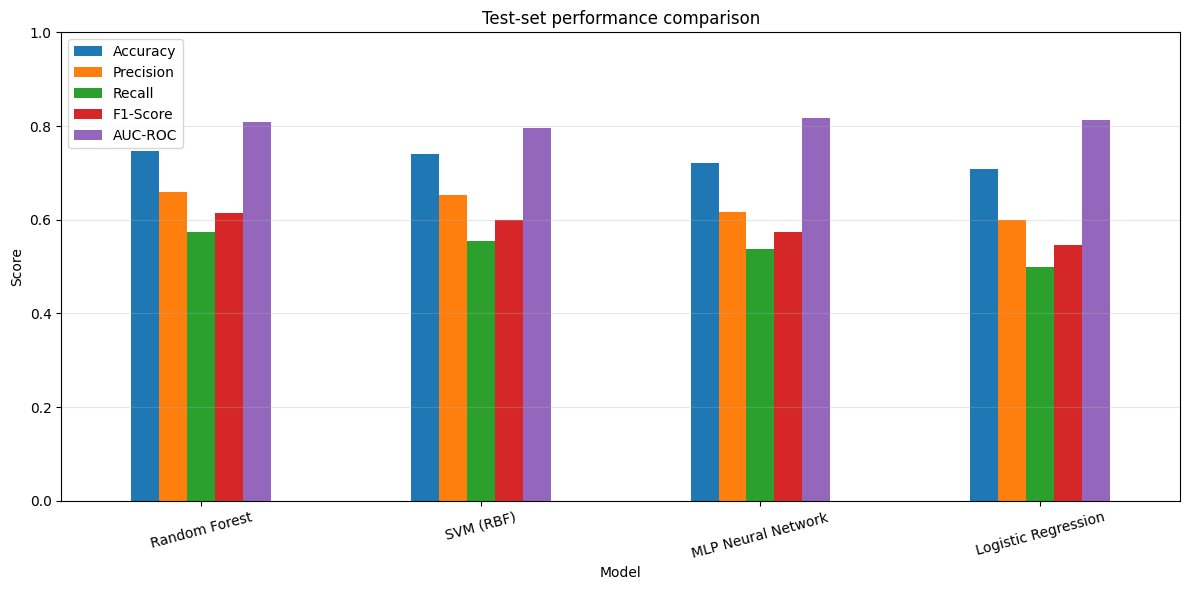

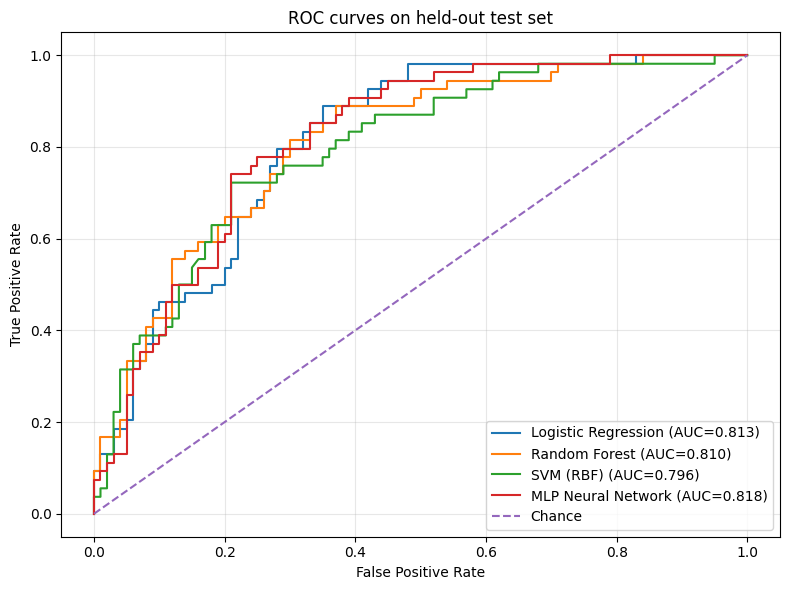

In [5]:
metric_cols = ["Accuracy", "Precision", "Recall", "F1-Score", "AUC-ROC"]
ax = results_df.set_index("Model")[metric_cols].plot(kind="bar", figsize=(12, 6), ylim=(0, 1), rot=15)
ax.set_title("Test-set performance comparison")
ax.set_ylabel("Score")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
for name, score in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, score)
    auc = roc_auc_score(y_test, score)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curves on held-out test set")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 6. Confusion matrices and classification reports

--- Logistic Regression ---
              precision    recall  f1-score   support

Non-diabetic       0.75      0.82      0.78       100
    Diabetic       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



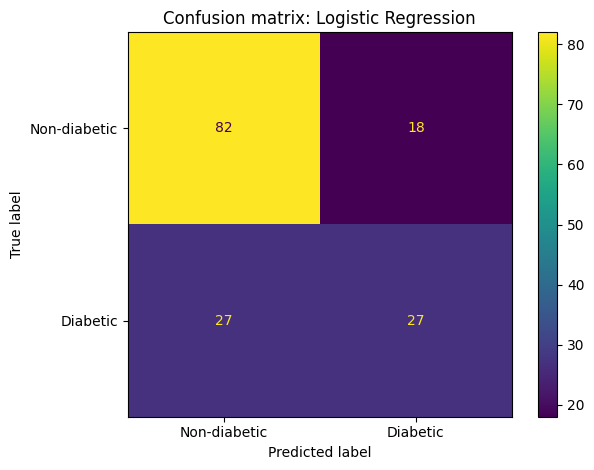

--- Random Forest ---
              precision    recall  f1-score   support

Non-diabetic       0.79      0.84      0.81       100
    Diabetic       0.66      0.57      0.61        54

    accuracy                           0.75       154
   macro avg       0.72      0.71      0.71       154
weighted avg       0.74      0.75      0.74       154



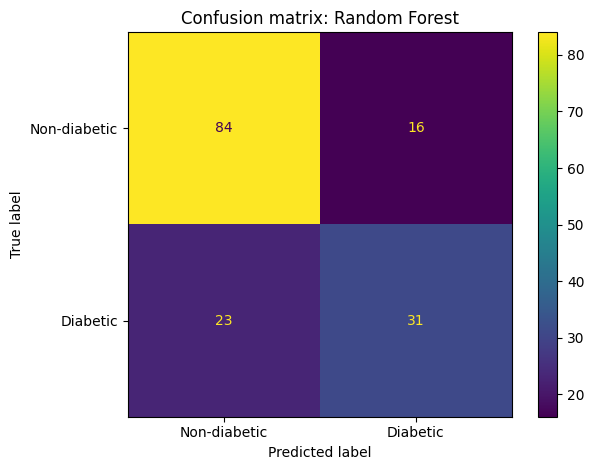

--- SVM (RBF) ---
              precision    recall  f1-score   support

Non-diabetic       0.78      0.84      0.81       100
    Diabetic       0.65      0.56      0.60        54

    accuracy                           0.74       154
   macro avg       0.71      0.70      0.70       154
weighted avg       0.73      0.74      0.73       154



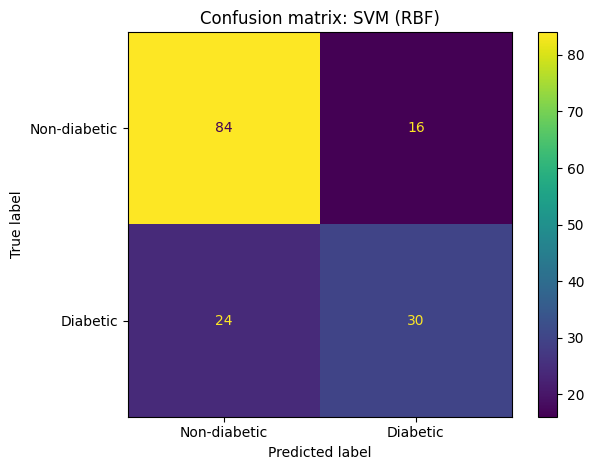

--- MLP Neural Network ---
              precision    recall  f1-score   support

Non-diabetic       0.77      0.82      0.79       100
    Diabetic       0.62      0.54      0.57        54

    accuracy                           0.72       154
   macro avg       0.69      0.68      0.68       154
weighted avg       0.71      0.72      0.72       154



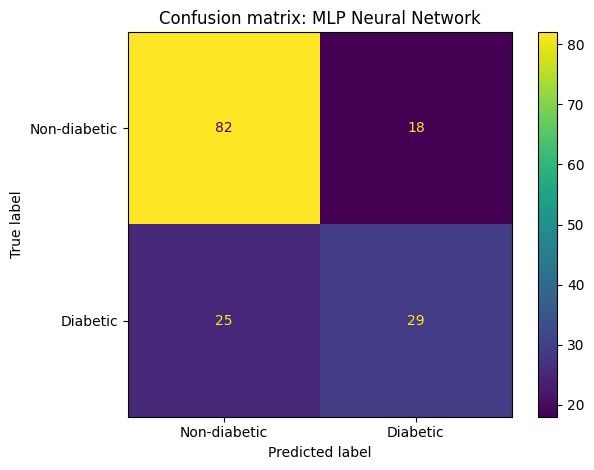

In [6]:
for name, pipe in fitted_models.items():
    pred = pipe.predict(X_test)
    print(f"--- {name} ---")
    print(classification_report(y_test, pred, target_names=["Non-diabetic", "Diabetic"], zero_division=0))
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=["Non-diabetic", "Diabetic"], cmap=None
    )
    plt.title(f"Confusion matrix: {name}")
    plt.tight_layout()
    plt.show()


## 7. Stratified 5-fold cross-validation
Cross-validation is run on the training split only; the held-out test set remains separate for the final evaluation. Scores may vary slightly across software versions.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}
cv_rows = []

for name, pipe in pipelines.items():
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1, error_score="raise")
    row = {"Model": name}
    for metric in scoring:
        row[f"{metric}_mean"] = scores[f"test_{metric}"].mean()
        row[f"{metric}_std"] = scores[f"test_{metric}"].std()
    cv_rows.append(row)

cv_results_df = pd.DataFrame(cv_rows).sort_values("f1_mean", ascending=False).reset_index(drop=True)
display(cv_results_df.round(4))
cv_results_df.to_csv("diabetes_cross_validation_results.csv", index=False)


Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

,Model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std
0,Logistic Regression,0.7882,0.0191,0.7638,0.0598,0.5748,0.0227,0.6545,0.0244,0.8434,0.0185
1,SVM (RBF),0.7801,0.0136,0.7415,0.0644,0.5842,0.0572,0.6485,0.0187,0.8333,0.0228
2,Random Forest,0.7687,0.0208,0.6980,0.0540,0.6028,0.0258,0.6453,0.0230,0.8244,0.0234
3,MLP Neural Network,0.7704,0.0108,0.7156,0.0617,0.5891,0.0784,0.6392,0.0263,0.8483,0.0135


## 8. Random Forest feature importance
Feature importance is model-specific and describes predictive contribution within this fitted Random Forest; it does not establish causation.

,Feature,Importance
0,Glucose,0.291758
1,BMI,0.161241
2,DiabetesPedigreeFunction,0.122544
3,Age,0.114428
4,Insulin,0.094925
5,BloodPressure,0.073150
6,Pregnancies,0.072910
7,SkinThickness,0.069045


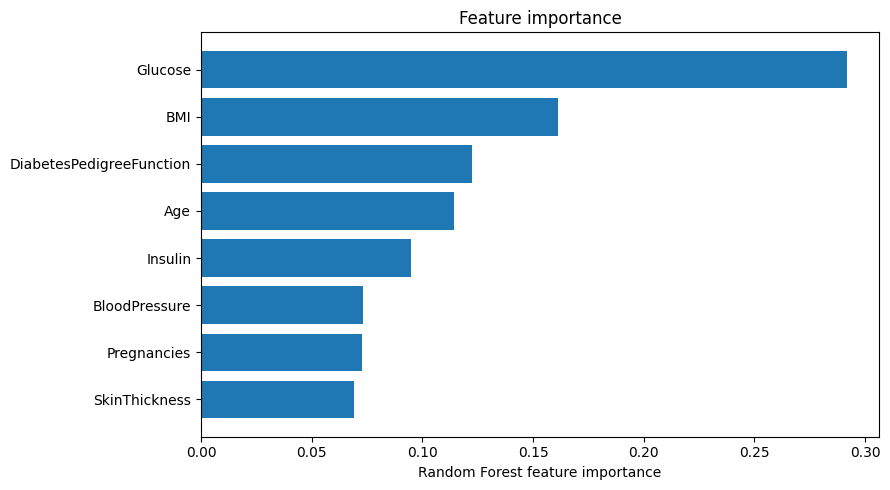

In [8]:
rf_pipe = fitted_models["Random Forest"]
rf = rf_pipe.named_steps["model"]
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf.feature_importances_
}).sort_values("Importance", ascending=False).reset_index(drop=True)
display(feature_importance)
feature_importance.to_csv("diabetes_feature_importance.csv", index=False)

plt.figure(figsize=(9, 5))
plt.barh(feature_importance["Feature"][::-1], feature_importance["Importance"][::-1])
plt.xlabel("Random Forest feature importance")
plt.title("Feature importance")
plt.tight_layout()
plt.show()


## 9. Summary of actual results
The following cell prints the best model by held-out test F1-score and records its metrics. Use these generated results in the final report rather than copying preliminary values from an earlier synopsis.

In [9]:
best = results_df.iloc[0]
print(f"Best model by test F1-score: {best['Model']}")
print("Held-out test metrics:")
for metric in metric_cols:
    print(f"  {metric}: {best[metric]:.4f}")

print("\nInterpretation:")
print("- Compare recall as well as F1 and AUC; no single metric is sufficient.")
print("- The test set is small, so estimates have uncertainty.")
print("- This model is for academic experimentation and must not be used to diagnose individuals.")


Best model by test F1-score: Random Forest
Held-out test metrics:
  Accuracy: 0.7468
  Precision: 0.6596
  Recall: 0.5741
  F1-Score: 0.6139
  AUC-ROC: 0.8096

Interpretation:
- Compare recall as well as F1 and AUC; no single metric is sufficient.
- The test set is small, so estimates have uncertainty.
- This model is for academic experimentation and must not be used to diagnose individuals.


## 10. Limitations and future work
1. The dataset is small and represents a specific population, so results may not generalize to other populations.
2. The binary label and available features are limited; performance does not imply clinical utility.
3. The default classification threshold may not be optimal for screening. Future work could assess threshold selection using validation data, calibration, confidence intervals, and external datasets.
4. Fairness, privacy, prospective validation, and clinician oversight would be necessary before any real-world use.

## References
- Smith, J. W. et al. (1988). “Using the ADAP learning algorithm to forecast the onset of diabetes mellitus.” *Proceedings of the Symposium on Computer Applications in Medical Care*.
- Breiman, L. (2001). “Random Forests.” *Machine Learning*, 45, 5–32.
- Pima Indians Diabetes dataset, commonly distributed through UCI Machine Learning Repository and Kaggle. Verify the specific repository/version used for formal citation.

**Academic integrity note:** Run all cells, inspect the generated outputs, and ensure your submitted report reflects the results produced on your machine.
